### Load data

In [1]:
# Importing Libraries and dataset for analysis
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

df = pd.read_csv('D2.csv')

### Inspect data

In [2]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5789 entries, 0 to 5788
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            5789 non-null   object 
 1   age               5789 non-null   object 
 2   height            5789 non-null   int64  
 3   weight            5789 non-null   int64  
 4   blood_type        5789 non-null   object 
 5   insurance         5789 non-null   object 
 6   income            5789 non-null   object 
 7   smoking           5789 non-null   object 
 8   alcohol           5789 non-null   float64
 9   contacts_count    5789 non-null   float64
 10  working           5789 non-null   object 
 11  worried           5789 non-null   float64
 12  covid19_positive  5789 non-null   int64  
dtypes: float64(3), int64(3), object(7)
memory usage: 588.1+ KB
None


### Blood type

In [3]:
print(df['blood_type'].describe())
print(df['blood_type'].value_counts())
print(df['blood_type'].unique())

count        5789
unique          9
top       unknown
freq         1884
Name: blood_type, dtype: object
blood_type
unknown    1884
ap         1279
op         1251
on          417
bp          394
an          244
abp         191
bn           91
abn          38
Name: count, dtype: int64
['op' 'bp' 'unknown' 'ap' 'on' 'abp' 'an' 'abn' 'bn']


### Prepare and split

In [4]:
def data_prep(df):
    df = pd.get_dummies(df)
    return df

df = data_prep(df)
rs = 10

# targe/input split
y=df['covid19_positive']
x=df.drop(['covid19_positive'],axis=1)

# Convert X into a numpy matrix 
X_mat = x.to_numpy(dtype=float) 

x_train,x_test, y_train,y_test = train_test_split(X_mat,y,test_size=0.3, random_state=rs, stratify=y)

### Inspect encoded data

In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5789 entries, 0 to 5788
Data columns (total 46 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   height                       5789 non-null   int64  
 1   weight                       5789 non-null   int64  
 2   alcohol                      5789 non-null   float64
 3   contacts_count               5789 non-null   float64
 4   worried                      5789 non-null   float64
 5   covid19_positive             5789 non-null   int64  
 6   gender_female                5789 non-null   bool   
 7   gender_male                  5789 non-null   bool   
 8   gender_other                 5789 non-null   bool   
 9   age_0_10                     5789 non-null   bool   
 10  age_100_110                  5789 non-null   bool   
 11  age_10_20                    5789 non-null   bool   
 12  age_20_30                    5789 non-null   bool   
 13  age_30_40         

### Standardise

In [6]:
#Scaling Numerical Values
# initialise a standard scaler object
scaler = StandardScaler()

# visualise min, max, mean and standard dev of data before scaling
print("Before scaling\n-------------")
for i in range(5):
    col = x_train[:,i]
    print("Variable #{}: min {}, max {}, mean {:.2f} and std dev {:.2f}".
          format(i, min(col), max(col), np.mean(col), np.std(col)))

# learn the mean and std.dev of variables from training data
# then use the learned values to transform training data
x_train_raw = x_train.copy()
x_test_raw = x_test.copy()
x_train = scaler.fit_transform(x_train, y_train)

print("After scaling\n-------------")
for i in range(5):
    col = x_train[:,i]
    print("Variable #{}: min {}, max {}, mean {:.2f} and std dev {:.2f}".
          format(i, min(col), max(col), np.mean(col), np.std(col)))

# use the statistic that you learned from training to transform test data
# NEVER learn from test data, this is supposed to be a set of dataset
# that the model has never seen before
x_test = scaler.transform(x_test)

Before scaling
-------------
Variable #0: min 110.0, max 238.0, mean 172.00 and std dev 10.93
Variable #1: min 44.0, max 180.0, mean 84.59 and std dev 23.10
Variable #2: min 0.0, max 14.0, mean 2.64 and std dev 3.09
Variable #3: min 0.0, max 21.0, mean 7.97 and std dev 6.79
Variable #4: min 1.0, max 5.0, mean 3.63 and std dev 0.73
After scaling
-------------
Variable #0: min -5.6731881981702275, max 6.039293583322545, mean -0.00 and std dev 1.00
Variable #1: min -1.7566695812374529, max 4.129715953323073, mean 0.00 and std dev 1.00
Variable #2: min -0.8547504201123084, max 3.6705208661341717, mean 0.00 and std dev 1.00
Variable #3: min -1.1740784926789536, max 1.9197121396460037, mean 0.00 and std dev 1.00
Variable #4: min -3.605808677507695, max 1.8684276511776476, mean -0.00 and std dev 1.00


### Default model

In [7]:
#Default Regression Model
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(random_state=rs)

# fit it to training data
model.fit(x_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",10
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

### Evaluate baseline

In [8]:
# Checking Accuracy score of Default Model
print("Train accuracy:", model.score(x_train, y_train))
print("Test accuracy:", model.score(x_test, y_test))

# classification report on test data
y_pred = model.predict(x_test)
print(classification_report(y_test, y_pred))

Train accuracy: 0.6984205330700889
Test accuracy: 0.6758779504893494
              precision    recall  f1-score   support

           0       0.71      0.77      0.74      1036
           1       0.61      0.53      0.57       701

    accuracy                           0.68      1737
   macro avg       0.66      0.65      0.66      1737
weighted avg       0.67      0.68      0.67      1737



### Coefficients

In [9]:
#printing the coeffecients of the model
print(model.coef_)

[[-0.20961608  0.30030166  0.06509881  0.00478947  0.11673408 -0.06424359
   0.05984161  0.04420318  0.00168065  0.19578519  0.04562918  0.12027619
   0.06260127  0.01417707  0.02795454 -0.18399144 -0.16778269 -0.02445297
   0.05091444 -0.03960346  0.00948078 -0.02487011  0.02446837 -0.03573434
   0.02105433 -0.01049565 -0.03713671  0.03713671  0.07693798 -0.37286977
  -0.02005698  0.34620521 -0.03864081  0.0191658   0.08596106 -0.09812962
   0.02856834  0.11341542 -0.03419557  0.02299271 -0.13153199  0.01027019
  -0.03719525  0.21936665 -0.13488238]]


### Coefficient names

In [10]:
feature_names = x.columns
coef = model.coef_[0]

# Only 20 features
coef = coef[:20]

for i in range(len(coef)):
    print(feature_names[i], ':', coef[i])

height : -0.20961608136589516
weight : 0.3003016648576666
alcohol : 0.06509881405120067
contacts_count : 0.004789472097841243
worried : 0.11673407804406738
gender_female : -0.06424359419725044
gender_male : 0.059841605841224464
gender_other : 0.0442031789277159
age_0_10 : 0.001680651222901119
age_100_110 : 0.19578519235686573
age_10_20 : 0.04562918485666419
age_20_30 : 0.12027618744042211
age_30_40 : 0.06260127285657456
age_40_50 : 0.014177068310754182
age_50_60 : 0.027954541518606414
age_60_70 : -0.18399144284245528
age_70_80 : -0.16778269431837234
blood_type_abn : -0.02445296762546129
blood_type_abp : 0.050914439369898944
blood_type_an : -0.03960345508236588


### Top features

In [11]:
# 5 important features
coef = model.coef_[0]
feat_names = x.columns

indices = np.argsort(np.absolute(coef))
indices = np.flip(indices, axis=0)

indices = indices[:5]

for i in indices:
    print(feature_names[i], ':', coef[i])

income_high : -0.3728697729599547
income_med : 0.3462052074924484
weight : 0.3003016648576666
working_travel critical : 0.21936664678003814
height : -0.20961608136589516


### Intercept

In [12]:
alpha = model.intercept_
print(alpha)

[-0.48956501]


### Grid search

In [13]:
from sklearn.pipeline import make_pipeline
params = {'logisticregression__C': [pow(10, x) for x in range(-6, 4)]}
cv = GridSearchCV(param_grid=params, estimator=make_pipeline(StandardScaler(), LogisticRegression(random_state=rs)), return_train_score=True, cv=10)
cv.fit(x_train_raw, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=10))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'logisticregression__C': [1e-06, 1e-05, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : the fold

### Tuned coefficients

In [14]:
# 5 important features
coef = cv.best_estimator_.named_steps['logisticregression'].coef_[0]
feat_names = x.columns

indices = np.argsort(np.absolute(coef))
indices = np.flip(indices, axis=0)

indices = indices[:5]

for i in indices:
    print(feature_names[i], ':', coef[i])

income_high : -0.3728697729599547
income_med : 0.3462052074924484
weight : 0.3003016648576666
working_travel critical : 0.21936664678003814
height : -0.20961608136589516


### CV results

In [15]:
result_set = cv.cv_results_
print(result_set)

{'mean_fit_time': array([0.00968478, 0.00883009, 0.00798626, 0.00789516, 0.00937097,
       0.00950112, 0.00962102, 0.00926945, 0.00948253, 0.01096106]), 'std_fit_time': array([0.00211966, 0.00107869, 0.00130163, 0.0013421 , 0.00389389,
       0.00081279, 0.00218671, 0.00213756, 0.00132743, 0.00197725]), 'mean_score_time': array([0.00121398, 0.00137691, 0.00121305, 0.00144243, 0.00131612,
       0.00135407, 0.0012922 , 0.0011775 , 0.00129576, 0.00125637]), 'std_score_time': array([0.0003187 , 0.00048887, 0.0002138 , 0.00044195, 0.00031222,
       0.00044603, 0.0002792 , 0.00028117, 0.00026687, 0.00026659]), 'param_logisticregression__C': masked_array(data=[1e-06, 1e-05, 0.0001, 0.001, 0.01, 0.1, 1.0, 10.0,
                   100.0, 1000.0],
             mask=[False, False, False, False, False, False, False, False,
                   False, False],
       fill_value=1e+20), 'params': [{'logisticregression__C': 1e-06}, {'logisticregression__C': 1e-05}, {'logisticregression__C': 0.0001}, 

### First fold

Total number of models:  10


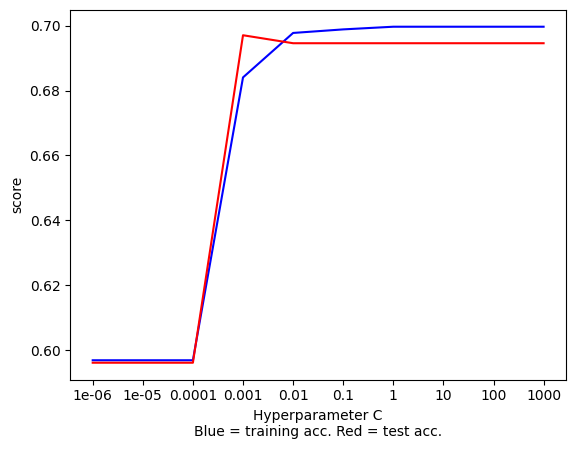

In [16]:
#Plot the train and test score of split 0
import matplotlib.pyplot as plt
train_result = result_set['split0_train_score']
test_result = result_set['split0_test_score']
print("Total number of models: ", len(test_result))
# plot Hyperparameter C values vs training and test accuracy score
plt.plot(range(0, len(train_result)), train_result, 'b', range(0,len(test_result)), test_result, 'r')
plt.xlabel('Hyperparameter C\nBlue = training acc. Red = test acc.')
plt.xticks(range(0, len(train_result)),[pow(10, x) for x in range(-6, 4)])
plt.ylabel('score')
plt.show()
#c=1

### Mean CV scores

Total number of models:  10


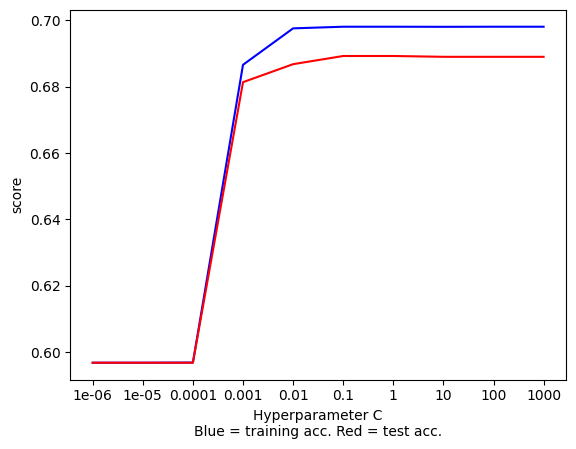

In [17]:
#Plot the mean train and test score for all splits
import matplotlib.pyplot as plt

train_result = result_set['mean_train_score']
test_result = result_set['mean_test_score']
print("Total number of models: ", len(test_result))
# plot Hyperparameter C values vs training and test accuracy score
plt.plot(range(0, len(train_result)), train_result, 'b', range(0,len(test_result)), test_result, 'r')
plt.xlabel('Hyperparameter C\nBlue = training acc. Red = test acc.')
plt.xticks(range(0, len(train_result)),[pow(10, x) for x in range(-6, 4)])
plt.ylabel('score')
plt.show()

### Best parameters

In [18]:
#Checking the best params
print(cv.best_params_)

{'logisticregression__C': 1}


### Evaluate tuned model

In [19]:


print("Train accuracy:", cv.score(x_train_raw, y_train))
print("Test accuracy:", cv.score(x_test_raw, y_test))

# classification report on test data
y_pred = cv.predict(x_test_raw)
print(classification_report(y_test, y_pred))

Train accuracy: 0.6984205330700889
Test accuracy: 0.6758779504893494
              precision    recall  f1-score   support

           0       0.71      0.77      0.74      1036
           1       0.61      0.53      0.57       701

    accuracy                           0.68      1737
   macro avg       0.66      0.65      0.66      1737
weighted avg       0.67      0.68      0.67      1737



### RFECV

In [20]:
from sklearn.feature_selection import RFECV
#using feature reduction 

rfe = RFECV(estimator = make_pipeline(StandardScaler(), LogisticRegression(random_state=rs)), cv=10, importance_getter='named_steps.logisticregression.coef_')
rfe.fit(x_train_raw, y_train) 

# comparing how many variables before and after
print("Original feature set", x_train.shape[1])
print("Number of features after elimination", rfe.n_features_)

Original feature set 45
Number of features after elimination 15


### Selected features

In [21]:
x_train_sel = rfe.transform(x_train_raw)
x_test_sel = rfe.transform(x_test_raw)

### Tune reduced model

In [22]:
# gridsearch CV
params = {'logisticregression__C': [pow(10, x) for x in range(-6, 4)]}

rfe_cv = GridSearchCV(param_grid=params, estimator=make_pipeline(StandardScaler(), LogisticRegression(random_state=rs)), cv=10)
rfe_cv.fit(x_train_sel, y_train)

# test the best model
print("Train accuracy:", rfe_cv.score(x_train_sel, y_train))
print("Test accuracy:", rfe_cv.score(x_test_sel, y_test))

y_pred = rfe_cv.predict(x_test_sel)
print(classification_report(y_test, y_pred))

# params for best model
print(rfe_cv.best_params_)

Train accuracy: 0.6942250740375123
Test accuracy: 0.6729994242947611
              precision    recall  f1-score   support

           0       0.70      0.78      0.74      1036
           1       0.61      0.51      0.56       701

    accuracy                           0.67      1737
   macro avg       0.66      0.65      0.65      1737
weighted avg       0.67      0.67      0.67      1737

{'logisticregression__C': 0.01}


### Reduced coefficients

In [23]:
# feature importance from the model
coef = rfe_cv.best_estimator_.named_steps['logisticregression'].coef_[0]
feature_names = x.columns[rfe.support_]

indices = np.argsort(np.absolute(coef))
indices = np.flip(indices, axis=0)

# include only 3 features
indices = indices[:3]

for i in indices:
    print(feature_names[i], ':', coef[i])

income_high : -0.3493881456014983
income_med : 0.32277932016432515
weight : 0.2500882725630771


### AUC

In [24]:
from sklearn.metrics import roc_auc_score

y_pred_proba_lr = model.predict_proba(x_test)
y_pred_proba_lr_cv = cv.predict_proba(x_test_raw)
y_pred_proba_rfe_cv = rfe_cv.predict_proba(x_test_sel)


roc_index_lr = roc_auc_score(y_test, y_pred_proba_lr[:, 1])
roc_index_lr_cv = roc_auc_score(y_test, y_pred_proba_lr_cv[:, 1])
roc_index_rfe_cv = roc_auc_score(y_test, y_pred_proba_rfe_cv[:, 1])

print("ROC index on test for `default model`:", roc_index_lr)
print("ROC index on test for `gridsearch cv`:", roc_index_lr_cv)
print("ROC index on test for `rfe_cv`:", roc_index_rfe_cv)

ROC index on test for `default model`: 0.7186245242593318
ROC index on test for `gridsearch cv`: 0.7186245242593318
ROC index on test for `rfe_cv`: 0.7179174538304351


### ROC coordinates

In [25]:
from sklearn.metrics import roc_curve

fpr_lr, tpr_lr, thresholds_lr = roc_curve(y_test, y_pred_proba_lr[:,1])
fpr_lr_cv, tpr_lr_cv, thresholds_lr_cv = roc_curve(y_test, y_pred_proba_lr_cv[:,1])
fpr_rfe_cv, tpr_rfe_cv, thresholds_rfe_cv = roc_curve(y_test, y_pred_proba_rfe_cv[:,1])

### ROC plot

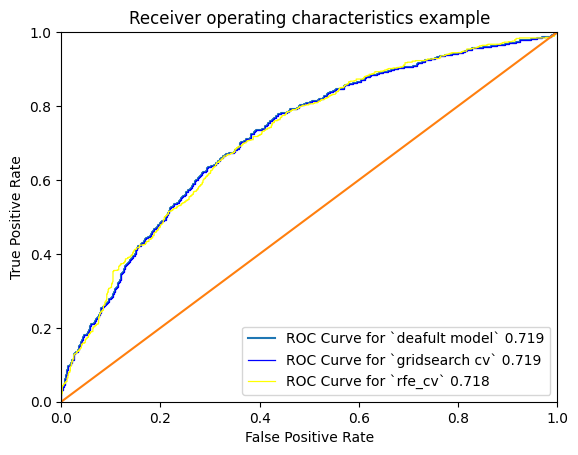

In [26]:
import matplotlib.pyplot as plt

plt.plot(fpr_lr, tpr_lr, label='ROC Curve for `deafult model` {:.3f}'.format(roc_index_lr))
plt.plot(fpr_lr_cv, tpr_lr_cv, label='ROC Curve for `gridsearch cv` {:.3f}'.format(roc_index_lr_cv), color='blue',lw=0.9)
plt.plot(fpr_rfe_cv, tpr_rfe_cv, label='ROC Curve for `rfe_cv` {:.3f}'.format(roc_index_rfe_cv), color='yellow',lw =0.9)

plt.plot([0, 1], [0, 1])
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristics example')
plt.legend(loc="lower right")
plt.show()